# 03 — Phase 5/6 Controlled Single-Variable Ablation & Statistical Validation (`EXP-0008`, `EXP-0012`)

**Data Integrity Rule:** Every table, confidence interval, p-value, and figure below is generated strictly from immutable saved outputs under `experiments/results/EXP-0008/` and `experiments/results/EXP-0012/` ($N=5$ unseen seeds, 75 core-pinned trials).


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df_s2 = pd.read_csv(REPO_ROOT / "experiments" / "results" / "EXP-0008" / "stage2_evaluation_summary.csv")
df_agg = pd.read_csv(REPO_ROOT / "experiments" / "results" / "EXP-0012" / "aggregated_summary.csv")
stat_tests = json.loads((REPO_ROOT / "experiments" / "results" / "EXP-0012" / "statistical_tests.json").read_text(encoding="utf-8"))

print(f"Loaded EXP-0008 ({len(df_s2)} Stage-2 baselines) & EXP-0012 ({len(df_agg)} scenario x arch summaries, {len(stat_tests)} Mann-Whitney U tests)")
df_s2


Loaded EXP-0008 (3 Stage-2 baselines) & EXP-0012 (15 scenario x arch summaries, 12 Mann-Whitney U tests)


,model,test_macro_f1,test_fpr_all_benign,test_fpr_flash_crowd,test_recall_udp_flood,test_recall_syn_flood
0,Static_Rate_Threshold(>=30pps),0.62573,0.70621,0.93985,1.0,0.98462
1,Window_LogisticRegression,1.00000,0.00000,0.00000,1.0,1.00000
2,Stage2_Window_LightGBM,1.00000,0.00000,0.00000,1.0,1.00000


## 1. Aggregated `EXP-0012` Ablation Table (Mean $\pm$ 95% CI, $N=5$ Unseen Seeds)


In [2]:
cols = [
    "scenario", "architecture", "controller_cpu_mean_pct_mean", "worker_cpu_mean_pct_mean",
    "event_loop_lag_p95_ms_mean", "s1_flow_table_occupancy_pct_mean", "table_full_errors_mean",
    "stage2_ipc_submitted_mean", "false_mitigations_benign_port_mean",
    "detection_to_mitigation_ms_mean", "benign_tcp_success_pct_mean", "benign_tcp_p95_ms_mean"
]
df_agg[cols]


,scenario,architecture,controller_cpu_mean_pct_mean,worker_cpu_mean_pct_mean,event_loop_lag_p95_ms_mean,s1_flow_table_occupancy_pct_mean,table_full_errors_mean,stage2_ipc_submitted_mean,false_mitigations_benign_port_mean,detection_to_mitigation_ms_mean,benign_tcp_success_pct_mean,benign_tcp_p95_ms_mean
0,spoof_udp_800pps,A0_Baseline_NoAI,73.676,0.240,1.512,99.980,8052.0,0.0,0.0,NaN,100.000,43.495
1,spoof_udp_800pps,A1_Sync_Light_LGBM,97.520,0.286,10.594,99.980,5798.2,0.0,0.0,NaN,79.958,1102.076
2,spoof_udp_800pps,A2_Decoupled_Async_WindowML,5.638,0.540,0.931,16.322,0.0,27.0,0.0,378.292,100.000,12.395
3,spoof_udp_800pps,A3_TwoStage_Gate_Decoupled_TableGuard,5.132,0.340,0.861,1.470,0.0,4.2,0.0,379.160,100.000,14.056
4,spoof_udp_800pps,A4_Static_Rate_Threshold,2.564,0.300,0.870,5.636,0.0,0.0,0.0,105.294,100.000,18.480
5,spoof_syn_800pps,A0_Baseline_NoAI,71.440,0.300,1.423,99.980,8052.4,0.0,0.0,NaN,100.000,39.108
6,spoof_syn_800pps,A1_Sync_Light_LGBM,96.838,0.328,9.744,99.980,7688.4,0.0,0.0,NaN,95.716,1793.534
7,spoof_syn_800pps,A2_Decoupled_Async_WindowML,5.818,0.400,0.892,17.384,0.0,26.8,0.0,404.984,100.000,11.318
8,spoof_syn_800pps,A3_TwoStage_Gate_Decoupled_TableGuard,4.422,0.280,0.893,1.440,0.0,4.2,0.0,315.512,100.000,16.584
9,spoof_syn_800pps,A4_Static_Rate_Threshold,2.612,0.300,0.818,5.882,0.0,0.0,0.0,112.038,100.000,13.182


## 2. Figure 5 — High-Rate Flood Ablation (`UDP 800 pps` & `TCP SYN 800 pps`, $N=5$, 95% CI)


In [3]:
arch_order = [
    "A0_Baseline_NoAI",
    "A1_Sync_Light_LGBM",
    "A2_Decoupled_Async_WindowML",
    "A3_TwoStage_Gate_Decoupled_TableGuard",
    "A4_Static_Rate_Threshold",
]
short_arch = ["A0\nNoAI", "A1\nSync LGBM", "A2\nDecoupled", "A3\n2-Stage+Guard", "A4\nStatic Rate"]

udp = df_agg[df_agg["scenario"] == "spoof_udp_800pps"].set_index("architecture").loc[arch_order]
syn = df_agg[df_agg["scenario"] == "spoof_syn_800pps"].set_index("architecture").loc[arch_order]

x = np.arange(len(arch_order))
w = 0.36
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9))

# Panel A: Controller CPU Mean (%)
axes[0].bar(x - w/2, udp["controller_cpu_mean_pct_mean"], width=w, yerr=udp["controller_cpu_mean_pct_ci95"], capsize=3, color="#2563eb", label="UDP Flood (800 pps)")
axes[0].bar(x + w/2, syn["controller_cpu_mean_pct_mean"], width=w, yerr=syn["controller_cpu_mean_pct_ci95"], capsize=3, color="#0ea5e9", label="TCP SYN Flood (800 pps)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_arch, fontsize=8.5)
axes[0].set_ylabel("Controller CPU Mean (% of Core 0)")
axes[0].set_ylim(0, 112)
axes[0].set_title("(a) Controller CPU Under 800 pps Floods")
axes[0].legend(loc="upper right", fontsize=8.5)

# Panel B: Peak s1 Software Flow-Table Occupancy (%)
axes[1].bar(x - w/2, udp["s1_flow_table_occupancy_pct_mean"], width=w, yerr=udp["s1_flow_table_occupancy_pct_ci95"], capsize=3, color="#ea580c", label="UDP Flood (800 pps)")
axes[1].bar(x + w/2, syn["s1_flow_table_occupancy_pct_mean"], width=w, yerr=syn["s1_flow_table_occupancy_pct_ci95"], capsize=3, color="#f59e0b", label="TCP SYN Flood (800 pps)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_arch, fontsize=8.5)
axes[1].set_ylabel("Peak s1 Flow-Table Occupancy (% of 4,096)")
axes[1].set_ylim(0, 114)
axes[1].set_title("(b) Flow-Table Guard Ablation (A2 vs. A3)")
axes[1].annotate("A3: 1.44–1.47%\n(11–12x < A2)", xy=(3, 4.0), xytext=(2.4, 46),
                 arrowprops=dict(arrowstyle="->", color="#111827", lw=1.2), fontsize=8.5, fontweight="bold")
axes[1].legend(loc="upper right", fontsize=8.5)

# Panel C: Legitimate New-TCP Setup Latency p95 (ms, log scale)
axes[2].bar(x - w/2, udp["benign_tcp_p95_ms_mean"], width=w, yerr=udp["benign_tcp_p95_ms_ci95"], capsize=3, color="#16a34a", label="UDP Flood (800 pps)")
axes[2].bar(x + w/2, syn["benign_tcp_p95_ms_mean"], width=w, yerr=syn["benign_tcp_p95_ms_ci95"], capsize=3, color="#10b981", label="TCP SYN Flood (800 pps)")
axes[2].set_yscale("log")
axes[2].set_xticks(x)
axes[2].set_xticklabels(short_arch, fontsize=8.5)
axes[2].set_ylabel("Benign New-TCP Setup p95 Latency (ms, log)")
axes[2].set_title("(c) Legitimate User New-Flow Setup Delay")
axes[2].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
out_fig = FIG_DIR / "fig05_exp0012_ablation_floods.png"
plt.savefig(out_fig, dpi=220, bbox_inches="tight")
print(f"Saved figure -> {out_fig}")
plt.show()


Saved figure -> C:\Users\sijan\Desktop\intern\research\figures\fig05_exp0012_ablation_floods.png


<Figure size 1650x490 with 3 Axes>

## 3. Figure 6 — Legitimate Benign Flash Crowd Control (`60 conn/s`, Zero Attack Traffic, $N=5$)
Proves why AI Stage-2 verification (`A3`) is essential over naive static rate limiting (`A4`).


Saved figure -> C:\Users\sijan\Desktop\intern\research\figures\fig06_exp0012_flash_crowd_vs_a4.png


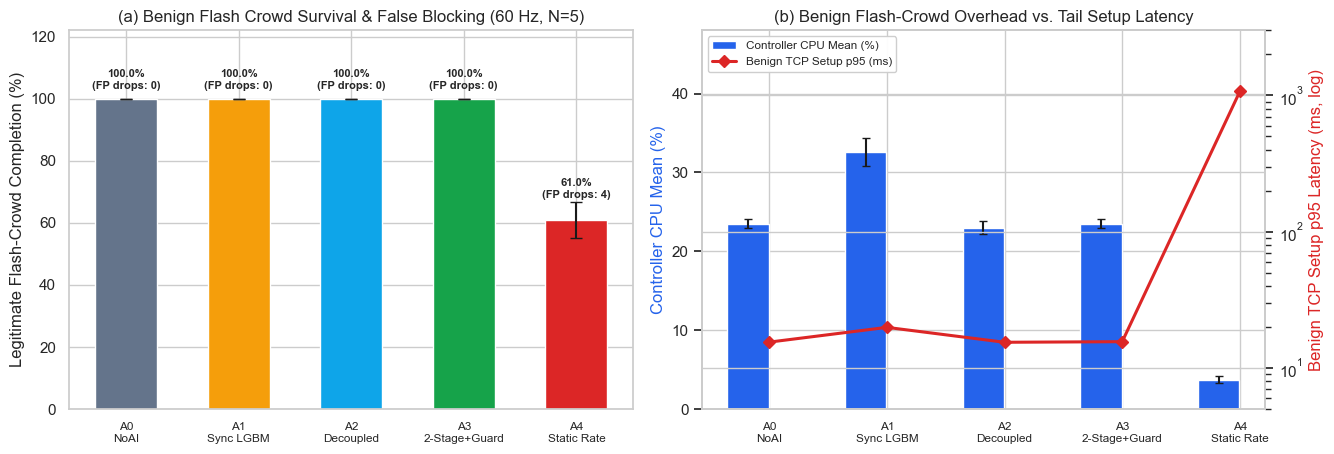

In [4]:
fc = df_agg[df_agg["scenario"] == "benign_flash_crowd_60hz"].set_index("architecture").loc[arch_order]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))

# Panel A: Legitimate Flash-Crowd Completion (%) & False Mitigations
ax1 = axes[0]
colors_ok = ["#64748b", "#f59e0b", "#0ea5e9", "#16a34a", "#dc2626"]
bars = ax1.bar(x, fc["benign_tcp_success_pct_mean"], yerr=fc["benign_tcp_success_pct_ci95"], capsize=4, color=colors_ok, width=0.55)
for i, (_, r) in enumerate(fc.iterrows()):
    fm = r["false_mitigations_benign_port_mean"]
    lbl = f"{r['benign_tcp_success_pct_mean']:.1f}%\n(FP drops: {fm:.0f})"
    ax1.text(i, r["benign_tcp_success_pct_mean"] + (6.5 if fm > 0 else 2.5), lbl, ha="center", va="bottom", fontsize=8, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(short_arch, fontsize=8.5)
ax1.set_ylabel("Legitimate Flash-Crowd Completion (%)")
ax1.set_ylim(0, 122)
ax1.set_title("(a) Benign Flash Crowd Survival & False Blocking (60 Hz, N=5)")

# Panel B: Controller CPU (%) & Setup Latency p95 (ms, log)
ax2 = axes[1]
ax2.bar(x - 0.18, fc["controller_cpu_mean_pct_mean"], width=0.35, yerr=fc["controller_cpu_mean_pct_ci95"], capsize=3, color="#2563eb", label="Controller CPU Mean (%)")
ax2.set_xticks(x)
ax2.set_xticklabels(short_arch, fontsize=8.5)
ax2.set_ylabel("Controller CPU Mean (%)", color="#2563eb")
ax2.set_ylim(0, 48)
ax2.set_title("(b) Benign Flash-Crowd Overhead vs. Tail Setup Latency")

ax2b = ax2.twinx()
ax2b.plot(x, fc["benign_tcp_p95_ms_mean"], marker="D", linewidth=2.2, color="#dc2626", label="Benign TCP Setup p95 (ms)")
ax2b.set_yscale("log")
ax2b.set_ylim(5, 3000)
ax2b.set_ylabel("Benign TCP Setup p95 Latency (ms, log)", color="#dc2626")

h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2b.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5, framealpha=0.95)

plt.tight_layout()
out_fig = FIG_DIR / "fig06_exp0012_flash_crowd_vs_a4.png"
plt.savefig(out_fig, dpi=220, bbox_inches="tight")
print(f"Saved figure -> {out_fig}")
plt.show()


## 4. Nonparametric Statistical Tests (Two-Sided Mann-Whitney U, $N=5$ vs. $N=5$)


In [5]:
pd.DataFrame(stat_tests)


,scenario,metric,proposed,baseline,proposed_mean,baseline_mean,mann_whitney_u,p_value
0,spoof_udp_800pps,controller_cpu_mean_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A1_Sync_Light_LGBM,5.132,97.520,0.0,0.01193
1,spoof_udp_800pps,benign_tcp_success_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A1_Sync_Light_LGBM,100.000,79.958,25.0,0.00669
2,spoof_udp_800pps,event_loop_lag_p95_ms,A3_TwoStage_Gate_Decoupled_TableGuard,A1_Sync_Light_LGBM,0.861,10.594,0.0,0.00794
3,spoof_udp_800pps,s1_flow_table_occupancy_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A2_Decoupled_Async_WindowML,1.470,16.322,0.0,0.00970
4,spoof_udp_800pps,controller_cpu_mean_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A0_Baseline_NoAI,5.132,73.676,0.0,0.00794
5,spoof_syn_800pps,controller_cpu_mean_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A1_Sync_Light_LGBM,4.422,96.838,0.0,0.01193
6,spoof_syn_800pps,benign_tcp_success_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A1_Sync_Light_LGBM,100.000,95.716,20.0,0.06680
7,spoof_syn_800pps,event_loop_lag_p95_ms,A3_TwoStage_Gate_Decoupled_TableGuard,A1_Sync_Light_LGBM,0.893,9.744,0.0,0.00794
8,spoof_syn_800pps,s1_flow_table_occupancy_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A2_Decoupled_Async_WindowML,1.440,17.384,0.0,0.00749
9,spoof_syn_800pps,controller_cpu_mean_pct,A3_TwoStage_Gate_Decoupled_TableGuard,A0_Baseline_NoAI,4.422,71.440,0.0,0.01193
